# Chapter 8 – Unsupervised Learning Techniques
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alirezatheh/handson-mlp-notes/blob/main/notebooks/08_unsupervised_learning_techniques.ipynb)
[![Open in Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/alirezatheh/handson-mlp-notes/blob/main/notebooks/08_unsupervised_learning_techniques.ipynb)

<style>ul {list-style-type: none;}</style>

Other than dimensionality reduction there are other unsupervised tasks:

*Clustering*
- The goal is to group similar instances together into clusters. Clustering is a great tool for data analysis, customer segmentation, recommender systems, search engines, image segmentation, semi-supervised learning, dimensionality reduction, and more.

*Anomaly detection (also called outlier detection)*
- The objective is to learn what “normal” data looks like, and then use that to detect abnormal instances. These instances are called *anomalies*, or *outliers*, while the normal instances are called *inliers*. Anomaly detection is useful in a wide variety of applications, such as fraud detection, detecting defective products in manufacturing, identifying new trends in time series, or removing outliers from a dataset before training another model, which can significantly improve the performance of the resulting model.

*Density estimation*
- This is the task of estimating the *probability density function* (PDF) of the random process that generated the dataset. Density estimation is commonly used for anomaly detection: instances located in very low-density regions are likely to be anomalies. It is also useful for data analysis and visualization.

## Clustering Algorithms: k-means and DBSCAN
<style>ul {list-style-type: none;}</style>

*Clustering* is the task of identifying similar instances and assigning them to *clusters*, or groups of similar instances.

Clustering is used in a wide variety of applications, including:

*Customer segmentation*
- We can cluster our customers based on their purchases and their activity on our website. This is useful to understand who our customers are and what they need, so we can adapt our products and marketing campaigns to each segment. e.g. it can be useful in *recommender systems* to suggest content that other users in the same cluster enjoyed.

*Data analysis*
- When we analyze a new dataset, it can be helpful to run a clustering algorithm, and then analyze each cluster separately.

*Dimensionality reduction*
- It is usually possible to measure each instance’s *affinity* with each cluster; affinity is any measure of how well an instance fits into a cluster. Each instance’s feature vector $\mathbf{x}$ can then be replaced with the vector of its cluster affinities. If there are *k* clusters, then this vector is *k*-dimensional which is typically much lower-dimensional than $\mathbf{x}$, but it can preserve enough information for further processing.

*Feature engineering*
- The cluster affinities can often be useful as extra features. e.g. we used *k*-means in Chapter 2 to add geographic cluster affinity features to the California housing dataset, and they helped us get better performance.

*Anomaly detection (also called outlier detection)*
- Any instance that has a low affinity to all the clusters is likely to be an anomaly. e.g. if we have clustered the users of our website based on their behavior, we can detect users with unusual behavior, such as an unusual number of requests per second.

*Semi-supervised learning*
- If we only have a few labels, we could perform clustering and propagate the labels to all the instances in the same cluster.

*Search engines*
- Some search engines let us search for images that are similar to a reference image. To build such a system, we would first apply a clustering algorithm to all the images in our database; similar images would end up in the same cluster. Then when a user provides a reference image, all we’d need to do is to find this image’s cluster, and we could then simply return all the images from this cluster.

*Image segmentation*
- By clustering pixels according to their color, then replacing each pixel’s color with the mean color of its cluster, it is possible to considerably reduce the number of different colors in an image.

There is no universal definition of what a *cluster* is: it really depends on the context, and different algorithms will capture different kinds of clusters. Some algorithms look for instances centered around a particular point, called a *centroid*. Others look for continuous regions of densely packed instances: these clusters can take on any shape. Some algorithms are hierarchical, looking for clusters of clusters.

### k-Means Clustering
It was proposed by Stuart P. Lloyd at Bell Labs in 1957 as a technique for pulse-code modulation, but it was only published in a paper [“Least Squares Quantization in PCM”](https://homl.info/36) outside of the company in 1982. In 1965, Edward W. Forgy had published virtually the same algorithm, so *k*-means is sometimes referred to as the Lloyd–Forgy algorithm.

Let’s train a *k*-means clusterer on the blobs dataset:

In [1]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# The exact arguments of make_blobs() are not important
blob_centers = np.array(
    [[0.2, 2.3], [-1.5, 2.3], [-2.8, 1.8], [-2.8, 2.8], [-2.8, 1.3]]
)
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])
X, y = make_blobs(
    n_samples=2000, centers=blob_centers, cluster_std=blob_std, random_state=7
)

k = 5
kmeans = KMeans(n_clusters=k, random_state=43)
y_pred = kmeans.fit_predict(X)

Now let’s plot them:

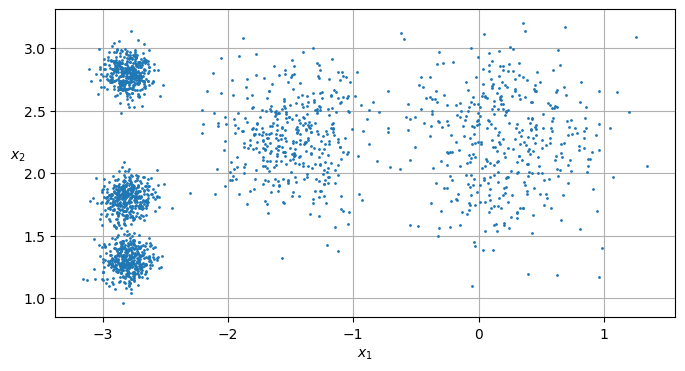

In [2]:
from typing import Optional

import matplotlib.pyplot as plt


def plot_clusters(X: np.ndarray, y: Optional[np.ndarray] = None) -> None:
    plt.scatter(X[:, 0], X[:, 1], c=y, s=1)
    plt.xlabel("$x_1$")
    plt.ylabel("$x_2$", rotation=0)


plt.figure(figsize=(8, 4))
plot_clusters(X)
plt.gca().set_axisbelow(True)
plt.grid()
plt.show()

Each instance was assigned to one of the 5 clusters:

In [3]:
y_pred

array([4, 0, 1, ..., 2, 1, 0], shape=(2000,), dtype=int32)

In [4]:
y_pred is kmeans.labels_

True

And the following 5 *centroids* (i.e., cluster centers) were estimated:

In [5]:
kmeans.cluster_centers_

array([[-2.80389616,  1.80117999],
       [ 0.20876306,  2.25551336],
       [-2.79290307,  2.79641063],
       [-1.46679593,  2.28585348],
       [-2.80037642,  1.30082566]])

Note that the `KMeans` instance preserves the labels of the instances it was
trained on. Somewhat confusingly, in this context, the *label* of an instance
is the index of the cluster that instance gets assigned to (they are not
targets, they are predictions):

In [6]:
kmeans.labels_

array([4, 0, 1, ..., 2, 1, 0], shape=(2000,), dtype=int32)

Of course, we can predict the labels of new instances:

In [7]:
X_new = np.array([[0, 2], [3, 2], [-3, 3], [-3, 2.5]])
kmeans.predict(X_new)

array([1, 1, 2, 2], dtype=int32)

Let’s plot the model’s decision boundaries. This gives us a *Voronoi diagram*:

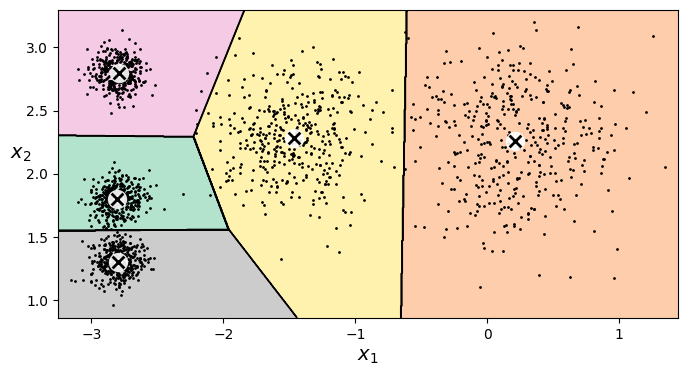

In [8]:
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline

plt.rc("font", size=14)
plt.rc("axes", labelsize=14, titlesize=14)
plt.rc("legend", fontsize=14)
plt.rc("xtick", labelsize=10)
plt.rc("ytick", labelsize=10)


def plot_data(X: np.ndarray) -> None:
    plt.plot(X[:, 0], X[:, 1], "k.", markersize=2)


def plot_centroids(
    centroids: np.ndarray,
    weights: Optional[np.ndarray] = None,
    circle_color: str = "w",
    cross_color: str = "k",
) -> None:
    if weights is not None:
        centroids = centroids[weights > weights.max() / 10]
    plt.scatter(
        centroids[:, 0],
        centroids[:, 1],
        marker="o",
        s=35,
        linewidths=8,
        color=circle_color,
        zorder=10,
        alpha=0.9,
    )
    plt.scatter(
        centroids[:, 0],
        centroids[:, 1],
        marker="x",
        s=2,
        linewidths=12,
        color=cross_color,
        zorder=11,
        alpha=1,
    )


def plot_decision_boundaries(
    clusterer: Pipeline,
    X: np.ndarray,
    resolution: int = 1000,
    show_centroids: bool = True,
    show_xlabels: bool = True,
    show_ylabels: bool = True,
) -> None:
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(
        np.linspace(mins[0], maxs[0], resolution),
        np.linspace(mins[1], maxs[1], resolution),
    )
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(
        Z, extent=(mins[0], maxs[0], mins[1], maxs[1]), cmap="Pastel2"
    )
    plt.contour(
        Z,
        extent=(mins[0], maxs[0], mins[1], maxs[1]),
        linewidths=1,
        colors="k",
    )
    plot_data(X)
    if show_centroids:
        plot_centroids(clusterer.cluster_centers_)

    if show_xlabels:
        plt.xlabel("$x_1$")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)


plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)
plt.show()

Not bad! Some of the instances near the edges were probably assigned to the wrong cluster, but overall it looks pretty good.

Instead of assigning each instance to a single cluster, which is called *hard clustering*, it can be useful to give each instance a score per cluster, which is called *soft clustering*. The score can be the distance between the instance and the centroid or a similarity score (or *affinity*). `transform()` method measures the distance from each instance to every centroid:

In [9]:
kmeans.transform(X_new).round(2)

array([[2.81, 0.33, 2.9 , 1.49, 2.89],
       [5.81, 2.8 , 5.85, 4.48, 5.84],
       [1.21, 3.29, 0.29, 1.69, 1.71],
       [0.73, 3.22, 0.36, 1.55, 1.22]])

#### The k-means algorithm
The *k*-means algorithm is one of the fastest clustering algorithms, and also one of the simplest:
1. First initialize $k$ centroids randomly: e.g., $k$ distinct instances are chosen randomly from the dataset and the centroids are placed at their locations.
2. Repeat until convergence (i.e., until the centroids stop moving):
   1. Assign each instance to the closest centroid.
   2. Update the centroids to be the mean of the instances that are assigned to them.

The `KMeans` class uses an optimized initialization technique by default. To get the original K-Means algorithm (for educational purposes only), we must set `init='random'` and `n_init=1`. More on this later in this chapter.

**Note**: The computational complexity is generally linear with $m$, $k$, $n$. However, this is only true when the data has a clustering structure. It also may converge to a local minimum.

#### Centroid initialization methods
If we know approximately where the centroids should be we can set:

In [10]:
good_init = np.array([[-3, 3], [-3, 2], [-3, 1], [-1, 2], [0, 2]])
kmeans = KMeans(n_clusters=5, init=good_init, random_state=42)
kmeans.fit(X)

,n_clusters,5
,init,"array([[-3, ... [ 0, 2]])"
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


To select the best model, we will need a way to evaluate a *k*-means model’s performance. Unfortunately, clustering is an unsupervised task, so we do not have the targets. But at least we can measure the distance between each instance and its centroid. This is the idea behind the *inertia* metric:

**Equation 8-1** A model’s inertia
$$
\text{inertia}=\sum_i\left\|\mathbf{x}^{(i)}-\mathbf{c}^{(i)}\right\|^2
$$
- $\mathbf{c}^{(i)}$: The closest centroid to the instance $\mathbf{x}^{(i)}$
  predicted by the model.

In [11]:
kmeans.inertia_

211.59853725816836

Scikit-Learn’s “greater is better” rule:

In [12]:
kmeans.score(X)

-211.59853725816836

In the original *k*-means algorithm, the centroids are just initialized randomly, and the algorithm simply runs a single iteration to gradually improve the centroids, as we saw above.

However, one major problem with this approach is that if you run *k*-means multiple times (or with different random seeds), it can converge to very different solutions.

So one approach to solve the *variability* issue is to simply run the *k*-means algorithm multiple times with different random initializations, and select the solution that minimizes the inertia using `n_init` (by default it is equal to 10 when using `init='random'`).

In [13]:
kmeans_rnd_10_inits = KMeans(
    n_clusters=5, init="random", n_init=10, random_state=2
)
kmeans_rnd_10_inits.fit(X)

,n_clusters,5
,init,'random'
,n_init,10
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,2
,copy_x,True
,algorithm,'lloyd'


In [14]:
kmeans_rnd_10_inits.inertia_

211.59853725816836

An important improvement to the k-means algorithm, *k-means++*, was proposed in a 2006 paper [“k-Means++: The Advantages of Careful Seeding”](https://homl.info/37) by David Arthur and Sergei Vassilvitskii. They introduced a smarter initialization step that tends to select centroids that are distant from one another. This makes the *k*-means algorithm much more likely to locate all important clusters, and less likely to converge to a suboptimal solution (just like spreading out fishing boats increases the chance of locating more schools of fish):
1. Take one centroid $c^{(1)}$, chosen uniformly at random from the dataset.
2. Take a new centroid $c^{(i)}$, choosing an instance $\mathbf{x}^{(i)}$ with probability: $D(\mathbf{x}^{(i)})^2/\sum_{j=1}^{m}{D(\mathbf{x}^{(j)})}^2$ where $D(\mathbf{x}^{(i)})$ is the distance between the instance $\mathbf{x}^{(i)}$ and the closest centroid that was already chosen. This probability distribution ensures that instances that are further away from already chosen centroids are much more likely to be selected as centroids.
3. Repeat the previous step until all $k$ centroids have been chosen.

When we set `init='k-means++'` (which is the default), the `KMeans` class actually uses a variant of *k*-means++ called *greedy k-means++*: instead of sampling a single centroid at each iteration, it samples multiple and picks the best one. When using this algorithm, `n_init` defaults to 1.

#### Accelerated k-means and mini-batch k-means
Another improvement to the k-means algorithm was proposed in a 2003 paper [“Using the Triangle Inequality to Accelerate k-Means”](https://homl.info/38) by Charles Elkan. On some large datasets with many clusters, the algorithm can be accelerated by avoiding many unnecessary distance calculations. Elkan achieved this by exploiting the triangle inequality and by keeping track of lower and upper bounds for distances between instances and centroids. It may not work and depends on the dataset. We can try by `algorithm='elkan'`.

Mini-batch k-means was proposed in a 2010 paper [“Web-Scale K-Means Clustering”](https://homl.info/39) by David Sculley. Instead of using the full dataset at each iteration, the algorithm is using mini-batches, moving the centroids just slightly at each iteration. This speeds up the algorithm.

In [15]:
from sklearn.cluster import MiniBatchKMeans

minibatch_kmeans = MiniBatchKMeans(n_clusters=5, random_state=42)
minibatch_kmeans.fit(X)

,n_clusters,5
,init,'k-means++'
,max_iter,100
,batch_size,1024
,verbose,0
,compute_labels,True
,random_state,42
,tol,0.0
,max_no_improvement,10
,init_size,None
,n_init,'auto'


In [16]:
minibatch_kmeans.inertia_

211.6594510571261

#### Finding the optimal number of clusters
The inertia is not a good performance metric when trying to choose $k$ because it keeps getting lower as we increase $k$. Let’s plot the inertia as a function of $k$. When we do this, the curve often contains an inflexion point called the *elbow*.

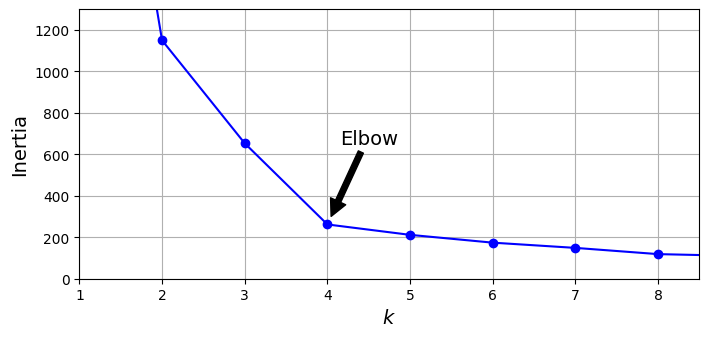

In [17]:
kmeans_per_k = [
    KMeans(n_clusters=k, random_state=43).fit(X) for k in range(1, 10)
]
inertias = [model.inertia_ for model in kmeans_per_k]

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, 10), inertias, "bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.annotate(
    "",
    xy=(4, inertias[3]),
    xytext=(4.45, 650),
    arrowprops=dict(facecolor="black", shrink=0.1),
)
plt.text(4.5, 650, "Elbow", horizontalalignment="center")
plt.axis([1, 8.5, 0, 1300])
plt.grid()
plt.show()

The inertia drops very quickly as we increase $k$ up to 4, but then it decreases much more slowly as we keep increasing $k$. This curve has roughly the shape of an arm, and there is an elbow at $k=4$. So, if we did not know better, we might think 4 was a good choice: any lower value would be dramatic, while any higher value would not help much, and we might just be splitting perfectly good clusters in half for no good reason.

This technique is rather coarse. A more precise (but also more computationally expensive) approach is to use the *silhouette score*, which is the mean *silhouette coefficient* over all the instances. An instance’s silhouette coefficient is equal to $(b–a)/\max(a,b)$, where $a$ is the mean distance to the other instances in the same cluster (i.e., the mean intra-cluster distance) and $b$ is the mean nearest-cluster distance (i.e., the mean distance to the instances of the next closest cluster, defined as the one that minimizes $b$, excluding the instance’s own cluster). The silhouette coefficient can vary between –1 and +1:
- A coefficient close to +1 means that the instance is well inside its own cluster and far from other clusters.
- A coefficient close to 0 means that it is close to a cluster boundary.
- A coefficient close to –1 means that the instance may have been assigned to the wrong cluster.

Let’s plot the silhouette score as a function of $k$:

In [18]:
from sklearn.metrics import silhouette_score

In [19]:
silhouette_score(X, kmeans.labels_)

0.6555176425728279

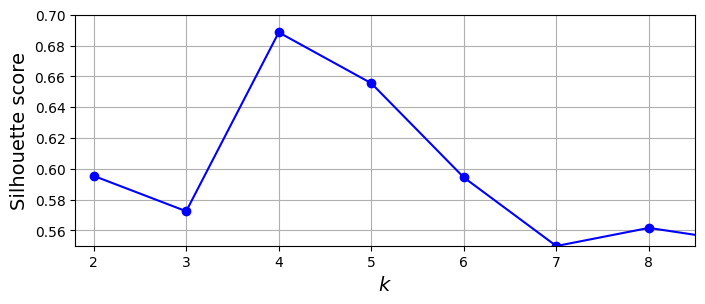

In [20]:
silhouette_scores = [
    silhouette_score(X, model.labels_) for model in kmeans_per_k[1:]
]

plt.figure(figsize=(8, 3))
plt.plot(range(2, 10), silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")
plt.axis([1.8, 8.5, 0.55, 0.7])
plt.grid()
plt.show()

An even more informative visualization is given when we plot every instance’s silhouette coefficient, sorted by the cluster they are assigned to and by the value of the coefficient. This is called a *silhouette diagram*. Each diagram contains one knife shape per cluster. The shape’s height indicates the number of instances in the cluster, and its width represents the sorted silhouette coefficients of the instances in the cluster (wider is better). The vertical dashed lines represent the mean silhouette score for each number of clusters. When most of the instances in a cluster have a lower coefficient than this score (i.e., if many of the instances stop short of the dashed line, ending to the left of it), then the cluster is rather bad since this means its instances are much too close to other clusters.

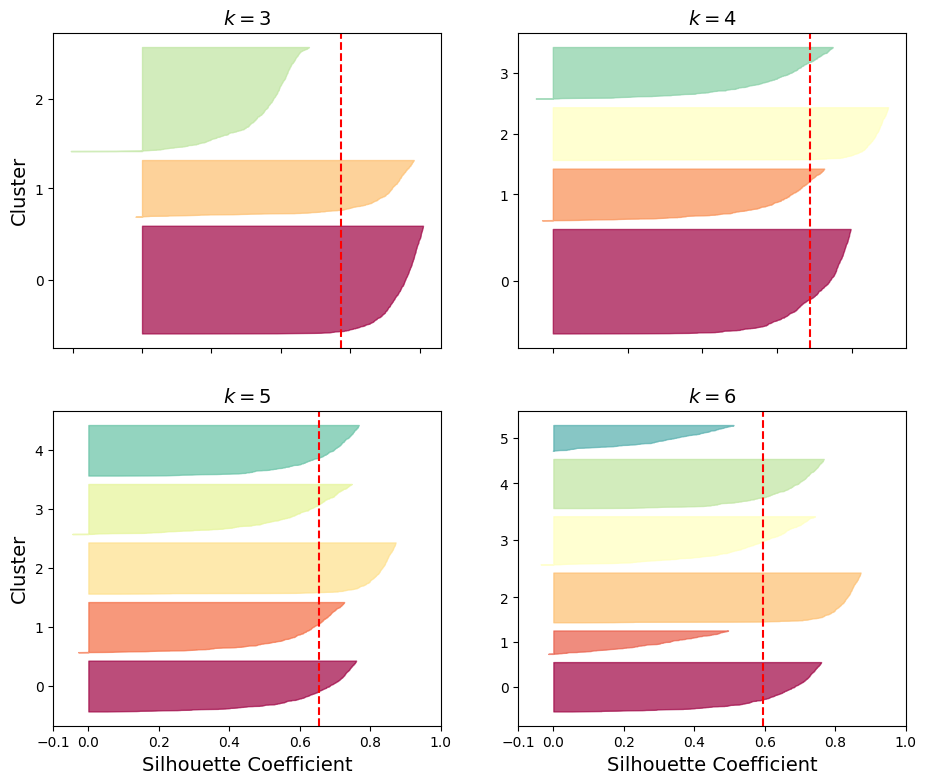

In [21]:
from matplotlib.ticker import FixedFormatter, FixedLocator
from sklearn.metrics import silhouette_samples

plt.figure(figsize=(11, 9))

for k in (3, 4, 5, 6):
    plt.subplot(2, 2, k - 2)

    y_pred = kmeans_per_k[k - 1].labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []
    for i in range(k):
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        color = plt.cm.Spectral(i / k)
        plt.fill_betweenx(
            np.arange(pos, pos + len(coeffs)),
            0,
            coeffs,
            facecolor=color,
            edgecolor=color,
            alpha=0.7,
        )
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))
    if k in (3, 5):
        plt.ylabel("Cluster")

    if k in (5, 6):
        plt.gca().set_xticks([-0.1, 0, 0.2, 0.4, 0.6, 0.8, 1])
        plt.xlabel("Silhouette Coefficient")
    else:
        plt.tick_params(labelbottom=False)

    plt.axvline(x=silhouette_scores[k - 2], color="red", linestyle="--")
    plt.title(f"$k={k}$")

plt.show()

As we can see, $k=5$ looks like the best option here, as all clusters are roughly the same size, and they all cross the dashed line, which represents the mean silhouette score.

### Limits of k-Means
- It is necessary to run the algorithm several times to avoid suboptimal solutions.
- We need to specify the number of clusters.
- Not behave very well when the clusters have:
  - Varying sizes
  - Different densities
  - Nonspherical shapes

**Tip**: It is important to scale the input features before running *k*-means, or the clusters may be very stretched and *k*-means will perform poorly. Scaling the features does not guarantee that all the clusters will be nice and spherical, but it generally helps *k*-means.

### Using Clustering for Image Segmentation
*Image segmentation* is the task of partitioning an image into multiple
segments. There are several variants:
- In *color segmentation*, pixels with a similar color get assigned to the same segment. This is sufficient in many applications, e.g. measuring how much total forest area there is in a region in satellite images.
- In *semantic segmentation*, all pixels that are part of the same object type get assigned to the same segment. For example, in a self-driving car’s vision system, all pixels that are part of a pedestrian’s image might be assigned to the “pedestrian” segment (there would be one segment containing all the pedestrians).
- In *instance segmentation*, all pixels that are part of the same individual object are assigned to the same segment. In this case there would be a different segment for each pedestrian.

Let’s download the ladybug image:

In [22]:
import urllib.request
from pathlib import Path

homlp_root = "https://github.com/ageron/handson-mlp/raw/main/"
filename = "ladybug.png"
filepath = Path(f"my_{filename}")
if not filepath.is_file():
    print("Downloading", filename)
    url = f"{homlp_root}/images/unsupervised_learning/{filename}"
    urllib.request.urlretrieve(url, filepath)

In [23]:
import PIL

image = np.asarray(PIL.Image.open(filepath))
image.shape

(533, 800, 3)

The third line uses advanced NumPy indexing; e.g. if the first 10 labels in `kmeans.labels_` are equal to 1, then the first 10 colors in `segmented_img` are equal to `kmeans.cluster_centers_[1]`:

In [24]:
X = image.reshape(-1, 3)
kmeans = KMeans(n_clusters=8, random_state=42).fit(X)
segmented_img = kmeans.cluster_centers_[kmeans.labels_]
segmented_img = segmented_img.reshape(image.shape)

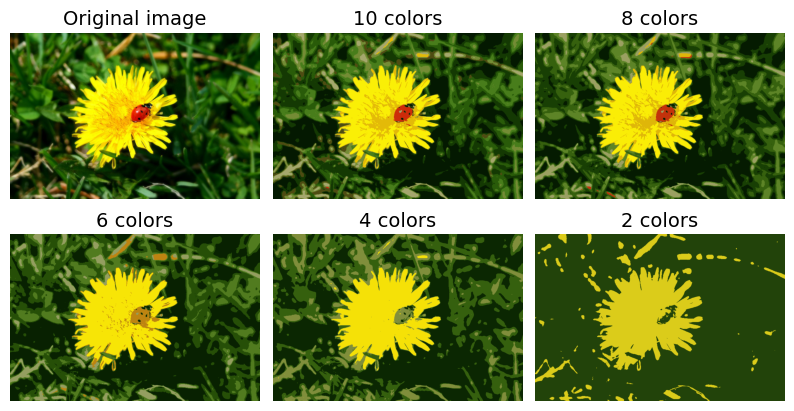

In [25]:
segmented_imgs = []
n_colors = (10, 8, 6, 4, 2)
for n_clusters in n_colors:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42).fit(X)
    segmented_img = kmeans.cluster_centers_[kmeans.labels_]
    segmented_imgs.append(segmented_img.reshape(image.shape))

plt.figure(figsize=(10, 5))
plt.subplots_adjust(wspace=0.05, hspace=0.1)

plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Original image")
plt.axis("off")

for idx, n_clusters in enumerate(n_colors):
    plt.subplot(2, 3, 2 + idx)
    plt.imshow(segmented_imgs[idx] / 255)
    plt.title(f"{n_clusters} colors")
    plt.axis("off")

plt.show()

### Using Clustering for Semi-Supervised Learning
Clustering can help choose which additional instances to label (e.g., near the cluster centroids). It can also be used to propagate the most common label in each cluster to the unlabeled instances in that cluster.

Let’s tackle the *digits dataset* which is a simple MNIST-like dataset containing 1,797 grayscale 8 $\times$ 8 images representing digits 0 to 9.

In [26]:
from sklearn.datasets import load_digits

X_digits, y_digits = load_digits(return_X_y=True)
X_train, y_train = X_digits[:1400], y_digits[:1400]
X_test, y_test = X_digits[1400:], y_digits[1400:]

Let’s look at the performance of a logistic regression model when we only have 50 labeled instances:

In [27]:
from sklearn.linear_model import LogisticRegression

n_labeled = 50
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_train[:n_labeled], y_train[:n_labeled])

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


In [28]:
log_reg.score(X_test, y_test)

0.7581863979848866

In [29]:
# Measure the accuracy when we use the whole training set
log_reg_full = LogisticRegression(max_iter=10_000)
log_reg_full.fit(X_train, y_train)
log_reg_full.score(X_test, y_test)

0.9093198992443325

It’s much less than the accuracy on the full training set of course. Let’s see how we can do better. First, let’s cluster the training set into 50 clusters, then for each cluster let’s find the image closest to the centroid. We will call these images the *representative images*:

In [30]:
k = 50
kmeans = KMeans(n_clusters=k, random_state=42)
X_digits_dist = kmeans.fit_transform(X_train)
representative_digit_idx = X_digits_dist.argmin(axis=0)
X_representative_digits = X_train[representative_digit_idx]

Now let’s plot these representative images and label them manually:

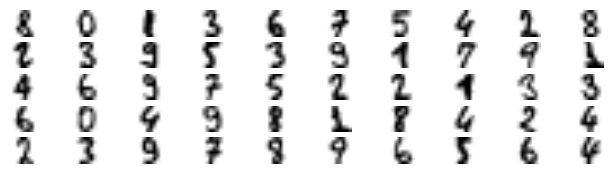

In [31]:
plt.figure(figsize=(8, 2))
for index, X_representative_digit in enumerate(X_representative_digits):
    plt.subplot(k // 10, 10, index + 1)
    plt.imshow(
        X_representative_digit.reshape(8, 8),
        cmap="binary",
        interpolation="bilinear",
    )
    plt.axis("off")

plt.show()

In [32]:
# fmt: off
y_representative_digits = np.array(
    [
        8, 0, 1, 3, 6, 7, 5, 4, 2, 8,
        2, 3, 9, 5, 3, 9, 1, 7, 9, 1,
        4, 6, 9, 7, 5, 2, 2, 1, 3, 3,
        6, 0, 4, 9, 8, 1, 8, 4, 2, 4,
        2, 3, 9, 7, 8, 9, 6, 5, 6, 4,
    ]
)
# fmt: on

Now we have a dataset with just 50 labeled instances, but instead of being completely random instances, each of them is a representative image of its cluster. Let’s see if the performance is any better:

In [33]:
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_representative_digits, y_representative_digits)
log_reg.score(X_test, y_test)

0.8312342569269522

But perhaps we can go one step further: what if we propagated the labels to all the other instances in the same cluster?

In [34]:
y_train_propagated = np.empty(len(X_train), dtype=np.int64)
for i in range(k):
    y_train_propagated[kmeans.labels_ == i] = y_representative_digits[i]

In [35]:
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_train, y_train_propagated)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


In [36]:
log_reg.score(X_test, y_test)

0.8664987405541562

Let’s see if we can do even better by ignoring the 50% instances that are farthest from their cluster center: this should eliminate most outliers. The following code first computes the distance from each instance to its closest cluster center, then for each cluster it sets the 50% largest distances to –1. Lastly, it creates a set without these instances marked with a –1 distance:

In [37]:
percentile_closest = 50

X_cluster_dist = X_digits_dist[np.arange(len(X_train)), kmeans.labels_]
for i in range(k):
    in_cluster = kmeans.labels_ == i
    cluster_dist = X_cluster_dist[in_cluster]
    cutoff_distance = np.percentile(cluster_dist, percentile_closest)
    above_cutoff = X_cluster_dist > cutoff_distance
    X_cluster_dist[in_cluster & above_cutoff] = -1

partially_propagated = X_cluster_dist != -1
X_train_partially_propagated = X_train[partially_propagated]
y_train_partially_propagated = y_train_propagated[partially_propagated]

In [38]:
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_train_partially_propagated, y_train_partially_propagated)
log_reg.score(X_test, y_test)

0.8790931989924433

Our propagated labels are actually pretty good: their accuracy is about 98.9%:

In [39]:
(y_train_partially_propagated == y_train[partially_propagated]).mean()

np.float64(0.9887640449438202)

**Tip**: Scikit-Learn also offers: `LabelSpreading` and `LabelPropagation` in the `sklearn.semi_supervised` package. Both construct a similarity matrix between all the instances, and iteratively propagate labels from labeled instances to similar unlabeled instances. There’s also a `SelfTrainingClassifier` in the same package: we give it a base classifier (e.g., `RandomForestClassifier`) and it trains it on the labeled instances, then uses it to predict labels for the unlabeled samples. It then updates the training set with the labels it is most confident about, and repeats this process of training and labeling until it cannot add labels anymore.

<div style="border: 1px solid">

#### Active Learning
To continue improving our model and our training set, the next step could be to do a few rounds of *active learning*, which is when a human expert interacts with the learning algorithm, providing labels for specific instances when the algorithm requests them. There are many strategies for active learning, but one of the most common ones is called *uncertainty sampling*. Here is how it works:
1. The model is trained on the labeled instances gathered so far, and this model is used to make predictions on all the unlabeled instances.
2. The instances for which the model is most uncertain (i.e., where its estimated probability is lowest) are given to the expert for labeling.
3. We iterate this process until the performance improvement stops being worth the labeling effort.

Other active learning strategies include labeling the instances that would result in the largest model change or the largest drop in the model’s validation error, or the instances that different models disagree on.
</div>

### DBSCAN
The *density-based spatial clustering of applications with noise* (DBSCAN) algorithm defines clusters as continuous regions of high density. Here is how it works:
- For each instance, the algorithm counts how many instances are located within a small distance $\varepsilon$ from it. This region is called the instance’s $\varepsilon$*-neighborhood*.
- If an instance has at least `min_samples` instances in its $\varepsilon$-neighborhood (including itself), then it is considered a *core instance*. In other words, core instances are those that are located in dense regions.
- All instances in the neighborhood of a core instance belong to the same cluster. This neighborhood may include other core instances; therefore, a long sequence of neighboring core instances forms a single cluster.

This algorithm works well if all the clusters are well separated by low-density regions.

In [40]:
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.05, random_state=42)
dbscan = DBSCAN(eps=0.05, min_samples=5)
dbscan.fit(X)

,eps,0.05
,min_samples,5
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


In [41]:
dbscan.labels_[:10]

array([ 0,  2, -1, -1,  1,  0,  0,  0,  2,  5])

Some instances have a cluster index equal to –1, which means that they are considered as anomalies.

In [42]:
dbscan.core_sample_indices_[:10]

array([ 0,  4,  5,  6,  7,  8, 10, 11, 12, 13])

In [43]:
# Core instances
dbscan.components_

array([[-0.02137124,  0.40618608],
       [-0.84192557,  0.53058695],
       [ 0.58930337, -0.32137599],
       ...,
       [ 1.66258462, -0.3079193 ],
       [-0.94355873,  0.3278936 ],
       [ 0.79419406,  0.60777171]], shape=(808, 2))

Although it has a `fit_predict()` method, the DBSCAN class does not have a `predict()` method. In other words, it cannot predict which cluster a new instance belongs to. This decision was made because different classification algorithms can be better for different tasks, so the authors decided to let the user choose which one to use.

In [44]:
from sklearn.neighbors import KNeighborsClassifier

dbscan = DBSCAN(eps=0.2).fit(X)
knn = KNeighborsClassifier(n_neighbors=50)
knn.fit(dbscan.components_, dbscan.labels_[dbscan.core_sample_indices_])

,n_neighbors,50
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [45]:
X_new = np.array([[-0.5, 0], [0, 0.5], [1, -0.1], [2, 1]])
knn.predict(X_new)

array([1, 0, 1, 0])

In [46]:
knn.predict_proba(X_new)

array([[0.18, 0.82],
       [1.  , 0.  ],
       [0.12, 0.88],
       [1.  , 0.  ]])

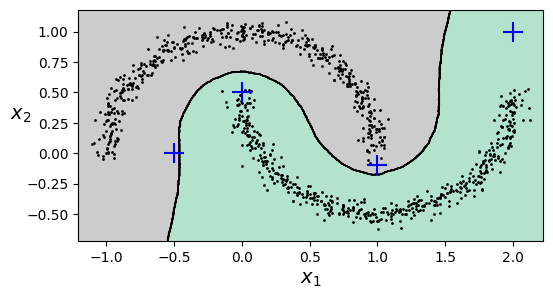

In [47]:
plt.figure(figsize=(6, 3))
plot_decision_boundaries(knn, X, show_centroids=False)
plt.scatter(X_new[:, 0], X_new[:, 1], c="b", marker="+", s=200, zorder=10)
plt.show()

We could also have chosen to train it on all the instances, or all but the anomalies.

Since there is no anomaly in the training set, the classifier always chooses a cluster, even when that cluster is far away. We can introduce a maximum distance, in which case the two instances that are far away from both clusters are classified as anomalies.

`kneighbors()` method given a set of instances, returns the distances and the indices of the $k$-nearest neighbors in the training set (two matrices, each with $k$ (n-neighbors) columns):

In [48]:
y_dist, y_pred_idx = knn.kneighbors(X_new, n_neighbors=1)
y_pred = dbscan.labels_[dbscan.core_sample_indices_][y_pred_idx]
y_pred[y_dist > 0.2] = -1
y_pred.ravel()

array([-1,  0,  1, -1])

DBSCAN pros:
- Simple yet powerful
- Clusters of any shape
- Robust to outliers
- Just two hyperparameters (`eps` and `min_samples`)

DBSCAN cons:
- Struggles if the density varies significantly across the clusters.
- Struggles if there’s no sufficiently low-density region around some clusters.
- Computational complexity is roughly $O(m^2n)$, so scales poorly with $m$.

**Tip**: For finding clusters of varying densities we can try *hierarchical DBSCAN* (HDBSCAN) using `sklearn.cluster.HDBSCAN`: it is often better than DBSCAN at finding clusters of varying densities.

### Other Clustering Algorithms
<style>*:not(li) > ul {list-style-type: none;}</style>

*Agglomerative clustering*
- A hierarchy of clusters is built from the bottom up. Think of many tiny bubbles floating on water and gradually attaching to each other until there’s one big group of bubbles. Similarly, at each iteration, it connects the nearest pair of clusters (starting with individual instances). If we drew a tree with a branch for every pair of clusters that merged, we would get a binary tree of clusters, where the leaves are the individual instances.
- Specs:
  - Clusters of various shapes
  - Flexible and informative cluster tree instead of forcing us to choose a particular cluster scale
  - Can be used with any pairwise distance.
  - Scales nicely with $m$ if we provide a sparse $m\times m$ connectivity matrix (e.g. returned by `sklearn.neighbors.kneighbors_graph()`).

In [49]:
from sklearn.cluster import AgglomerativeClustering

X = np.array([0, 2, 5, 8.5]).reshape(-1, 1)
agg = AgglomerativeClustering(linkage="complete").fit(X)

In [50]:
def learned_parameters(estimator: Pipeline) -> list[str]:
    return [
        attrib
        for attrib in dir(estimator)
        if attrib.endswith("_") and not attrib.startswith("_")
    ]

In [51]:
learned_parameters(agg)

['children_',
 'labels_',
 'n_clusters_',
 'n_connected_components_',
 'n_features_in_',
 'n_leaves_']

In [52]:
agg.children_

array([[0, 1],
       [2, 3],
       [4, 5]])

<style>*:not(li) > ul {list-style-type: none;}</style>

*BIRCH*
- The *balanced iterative reducing and clustering using hierarchies* (BIRCH) algorithm was designed specifically for very large datasets, and if $n<20$ it can be faster than batch *k*-means, with similar results. During training, it builds a tree structure containing just enough information to quickly assign each new instance to a cluster, without having to store all the instances in the tree: this approach allows it to use limited memory while handling huge datasets.

*Mean-shift*
- This algorithm starts by placing a circle centered on each instance; then for each circle it computes the mean of all the instances located within it, and it shifts the circle so that it is centered on the mean. Next, it iterates this mean-shifting step until all the circles stop moving (i.e., until each of them is centered on the mean of the instances it contains). Mean-shift shifts the circles in the direction of higher density, until each of them has found a local density maximum. Finally, all the instances whose circles have settled in the same place (or close enough) are assigned to the same cluster.
- Specs:
  - Clusters of any shape
  - Few hyperparameters (just one, the radius of the circles, called the *bandwidth*.)
  - Relies on local density estimation.
  - Unlike DBSCAN, mean-shift tends to chop clusters into pieces when they have internal density variations.
  - Computational complexity is $O(m^2n)$, scales poorly with $m$.

*Affinity propagation*
- Instances repeatedly exchange messages between one another until every instance has elected another instance (or itself) to represent it. These elected instances are called *exemplars*. Each exemplar and all the instances that elected it form one cluster. In real-life politics, we typically want to vote for a candidate whose opinions are similar to ours, but we also want them to win the election, so we might choose a candidate we don’t fully agree with, but who is more popular. We typically evaluate popularity through polls. Affinity propagation works in a similar way, and it tends to choose exemplars located near the center of clusters, similar to *k*-means. But unlike with *k*-means, we don’t have to pick a number of clusters ahead of time: it is determined during training.
- Specs:
  - Clusters of different sizes
  - Computational complexity of $O(m^2)$, scales poorly with $m$.

*Spectral clustering*
- Takes a similarity matrix between the instances and creates a low-dimensional embedding from it (i.e., it reduces the matrix’s dimensionality), then it uses another clustering algorithm in this low-dimensional space (Scikit-Learn’s implementation uses *k*-means).
- Specs:
  - Can capture complex cluster structures.
  - Can be used to cut graphs (e.g., to identify clusters of friends on a social network).
  - Scales poorly with $m$.
  - Does not behave well when the clusters have very different sizes.

In [53]:
from sklearn.cluster import SpectralClustering

X, y = make_moons(n_samples=1000, noise=0.05, random_state=42)
sc1 = SpectralClustering(n_clusters=2, gamma=100, random_state=42)
sc1.fit(X)

,n_clusters,2
,eigen_solver,None
,n_components,None
,random_state,42
,n_init,10
,gamma,100
,affinity,'rbf'
,n_neighbors,10
,eigen_tol,'auto'
,assign_labels,'kmeans'
,degree,3


In [54]:
sc1.affinity_matrix_.round(2)

array([[1. , 0. , 0. , ..., 0. , 0. , 0. ],
       [0. , 1. , 0.3, ..., 0. , 0. , 0. ],
       [0. , 0.3, 1. , ..., 0. , 0. , 0. ],
       ...,
       [0. , 0. , 0. , ..., 1. , 0. , 0. ],
       [0. , 0. , 0. , ..., 0. , 1. , 0. ],
       [0. , 0. , 0. , ..., 0. , 0. , 1. ]], shape=(1000, 1000))

In [55]:
sc2 = SpectralClustering(n_clusters=2, gamma=1, random_state=42)
sc2.fit(X)

,n_clusters,2
,eigen_solver,None
,n_components,None
,random_state,42
,n_init,10
,gamma,1
,affinity,'rbf'
,n_neighbors,10
,eigen_tol,'auto'
,assign_labels,'kmeans'
,degree,3


In [56]:
def plot_spectral_clustering(
    sc: Pipeline,
    X: np.ndarray,
    size: float,
    alpha: float,
    show_xlabels: bool = True,
    show_ylabels: bool = True,
) -> None:
    plt.scatter(
        X[:, 0],
        X[:, 1],
        marker="o",
        s=size,
        c="gray",
        alpha=alpha,
    )
    plt.scatter(X[:, 0], X[:, 1], marker="o", s=30, c="w")
    plt.scatter(
        X[:, 0], X[:, 1], marker=".", s=10, c=sc.labels_, cmap="Paired"
    )

    if show_xlabels:
        plt.xlabel("$x_1$")
    else:
        plt.tick_params(labelbottom=False)
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)
    plt.title(f"RBF gamma={sc.gamma}")

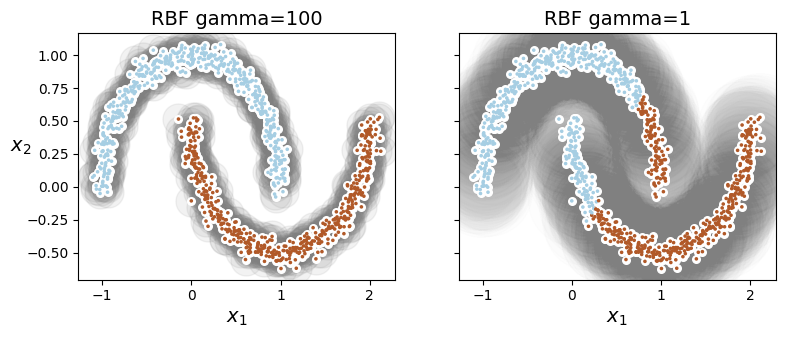

In [57]:
plt.figure(figsize=(9, 3.2))

plt.subplot(121)
plot_spectral_clustering(sc1, X, size=500, alpha=0.1)

plt.subplot(122)
plot_spectral_clustering(sc2, X, size=4000, alpha=0.01, show_ylabels=False)

plt.show()

## Gaussian Mixtures
A *Gaussian mixture model* (GMM) is a probabilistic model that assumes that the instances were generated from a mixture of several Gaussian distributions whose parameters are unknown. All the instances generated from a single Gaussian distribution form a cluster that typically looks like an ellipsoid. Each cluster can have a different ellipsoidal shape, size, density, and orientation (in contrast, *k*-means implicitly assumes that clusters all have a similar size and density, and are all roughly round).

There are several GMM variants. In the simplest, implemented in the `GaussianMixture` class, we must know in advance the number $k$ of Gaussian distributions. The dataset $\mathbf{X}$ is assumed to have been generated through the following probabilistic process:
- For each instance, a cluster is picked randomly from among $k$ clusters. The probability of choosing the $j^\text{th}$ cluster is the cluster’s weight $\phi^{(j)}$. The index of the cluster chosen for the $i^\text{th}$ instance is denoted $z^{(i)}$.
- If the $i^\text{th}$ instance was assigned to the $j^\text{th}$ cluster (i.e., $z^{(i)}=j$), then the location $\mathbf{x}^{(i)}$ of this instance is sampled randomly from the Gaussian distribution with mean $\boldsymbol{\mu}^{(j)}$ and covariance matrix $\mathbf{\Sigma}^{(j)}$. This is denoted $\mathbf{x}^{(i)}\sim\mathscr{N}(\boldsymbol{\mu}^{(j)}, \mathbf{\Sigma}^{(j)})$.

Given the dataset $\mathbf{X}$, we typically want to estimate the weights $\boldsymbol{\phi}$ and all the distribution parameters $\boldsymbol{\mu}^{(1)}$ to $\boldsymbol{\mu}^{(k)}$ and $\mathbf{\Sigma}^{(1)}$ to $\mathbf{\Sigma}^{(k)}$.

Let’s generate the same dataset as earlier with three ellipsoids (the one *k*-means had trouble with):

In [58]:
X1, y1 = make_blobs(n_samples=1000, centers=((4, -4), (0, 0)), random_state=42)
X1 = X1.dot(np.array([[0.374, 0.95], [0.732, 0.598]]))
X2, y2 = make_blobs(n_samples=250, centers=1, random_state=42)
X2 = X2 + [6, -8]
X = np.r_[X1, X2]
y = np.r_[y1, y2]

Let’s train a Gaussian mixture model on the previous dataset:

In [59]:
from sklearn.mixture import GaussianMixture

gm = GaussianMixture(n_components=3, n_init=10, random_state=42)
gm.fit(X)

,n_components,3
,covariance_type,'full'
,tol,0.001
,reg_covar,1e-06
,max_iter,100
,n_init,10
,init_params,'kmeans'
,weights_init,None
,means_init,None
,precisions_init,None
,random_state,42


Let’s look at the parameters that the algorithm estimated:

In [60]:
gm.weights_

array([0.40005972, 0.20961444, 0.39032584])

Two of the three clusters were generated with 500 instances each, and the third cluster with 250 instances. So the true cluster weights are 0.4, 0.4, and 0.2, respectively.

In [61]:
gm.means_

array([[-1.40764129,  1.42712848],
       [ 3.39947665,  1.05931088],
       [ 0.05145113,  0.07534576]])

In [62]:
gm.covariances_

array([[[ 0.63478217,  0.72970097],
        [ 0.72970097,  1.16094925]],

       [[ 1.14740131, -0.03271106],
        [-0.03271106,  0.95498333]],

       [[ 0.68825143,  0.79617956],
        [ 0.79617956,  1.21242183]]])

This class relies on the *expectation-maximization* (EM) algorithm which is a generalization of *k*-means that not only finds the cluster centers ($\boldsymbol{\mu}^{(1)}$ to $\boldsymbol{\mu}^{(k)}$), but also their size, shape, and orientation ($\mathbf{\Sigma}^{(1)}$ to $\mathbf{\Sigma}^{(k)}$) as well as their relative weights ($\phi^{(1)}$ to $\phi^{(k)}$). It also initializes the cluster parameters randomly, then it repeats two steps until convergence:
1. For each instance, during the *expectation step*, the algorithm estimates the probability that it belongs to each cluster (based on the current cluster parameters).
2. Then, during the *maximization step*, each cluster is updated using *all* the instances in the dataset, with each instance weighted by the estimated probability that it belongs to that cluster. These probabilities are called the *responsibilities* of the clusters for the instances. During this step, each cluster’s update will mostly be impacted by the instances it is most responsible for.

**Warning**: Like *k*-means, EM can end up converging to poor solutions, so it needs to be run several times, keeping only the best solution. This is why we set `n_init=10`. Be careful: by default `n_init=1`.

Let’s check if it’s converged:

In [63]:
gm.converged_

True

How many iterations did it take to converge?

In [64]:
gm.n_iter_

4

Hard clustering:

In [65]:
gm.predict(X)

array([2, 2, 0, ..., 1, 1, 1], shape=(1250,))

Soft clustering:

In [66]:
gm.predict_proba(X).round(3)

array([[0.   , 0.023, 0.977],
       [0.001, 0.016, 0.983],
       [1.   , 0.   , 0.   ],
       ...,
       [0.   , 1.   , 0.   ],
       [0.   , 1.   , 0.   ],
       [0.   , 1.   , 0.   ]], shape=(1250, 3))

This is a generative model, so we can sample new instances from it:

In [67]:
X_new, y_new = gm.sample(6)
X_new

array([[-2.32491052,  1.04752548],
       [-1.16654983,  1.62795173],
       [ 1.84860618,  2.07374016],
       [ 3.98304484,  1.49869936],
       [ 3.8163406 ,  0.53038367],
       [ 0.38079484, -0.56239369]])

In [68]:
y_new

array([0, 0, 1, 1, 1, 2])

To estimate the density of the model at any given location, we can use `score_samples()` which estimates the log of the *probability density function* (PDF) at that location. The greater the score, the higher the density:

In [69]:
gm.score_samples(X).round(2)

array([-2.61, -3.57, -3.33, ..., -3.51, -4.4 , -3.81], shape=(1250,))

Now let’s plot the resulting decision boundaries (dashed lines) and density contours:

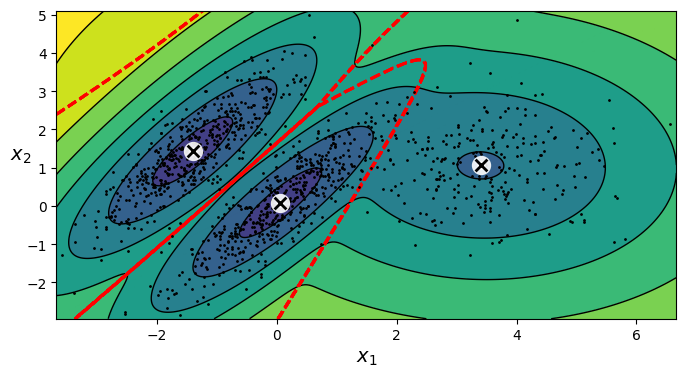

In [70]:
from matplotlib.colors import LogNorm


def plot_gaussian_mixture(
    clusterer: Pipeline,
    X: np.ndarray,
    resolution: int = 1000,
    show_ylabels: bool = True,
) -> None:
    mins = X.min(axis=0) - 0.1
    maxs = X.max(axis=0) + 0.1
    xx, yy = np.meshgrid(
        np.linspace(mins[0], maxs[0], resolution),
        np.linspace(mins[1], maxs[1], resolution),
    )
    Z = -clusterer.score_samples(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(
        xx,
        yy,
        Z,
        norm=LogNorm(vmin=1.0, vmax=30.0),
        levels=np.logspace(0, 2, 12),
    )
    plt.contour(
        xx,
        yy,
        Z,
        norm=LogNorm(vmin=1.0, vmax=30.0),
        levels=np.logspace(0, 2, 12),
        linewidths=1,
        colors="k",
    )

    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    plt.contour(xx, yy, Z, linewidths=2, colors="r", linestyles="dashed")

    plt.plot(X[:, 0], X[:, 1], "k.", markersize=2)
    plot_centroids(clusterer.means_, clusterer.weights_)

    plt.xlabel("$x_1$")
    if show_ylabels:
        plt.ylabel("$x_2$", rotation=0)
    else:
        plt.tick_params(labelleft=False)


plt.figure(figsize=(8, 4))
plot_gaussian_mixture(gm, X)
plt.show()

EM can struggle when there are:
- Many dimensions
- Many clusters
- Few instances

<style>ul {list-style-type: none;}</style>

We can impose constraints on the covariance matrices that the algorithm looks for by setting the `covariance_type` hyperparameter:

`'spherical'`
- All clusters must be spherical, but they can have different diameters (i.e., different variances).

`'diag'`
- Clusters can take on any ellipsoidal shape of any size, but the ellipsoid’s axes must be parallel to the coordinate axes (i.e., the covariance matrices must be diagonal).

`'tied'`
- All clusters must have the same shape, which can be any ellipsoid (i.e., they all share the same covariance matrix).

`'full'`
- No constraint, all clusters can take on any ellipsoidal shape of any size. This is default.

<center>
  <img
    src="../images/08/covariance_type.png"
    onerror="
      this.onerror = null;
      const repo = 'https://github.com/alirezatheh/handson-mlp-notes/blob/main';
      this.src = repo + this.src.split('..')[1];
    "
  >
</center>

**Note**: Computational complexity of training a `GaussianMixture`:
- `'spherical'` or `'diag'`: $O(kmn)$, assuming the data has a clustering
  structure.
- `'tied'` or `'full'`: $O(kmn^2+kn^3)$, so it doesn’t scale with $n$.

### Using Gaussian Mixtures for Anomaly Detection
Instances located in low-density regions can be considered anomalies. We must define what density threshold we want to use. e.g. in a manufacturing company that tries to detect defective products, the ratio of defective products is usually well-known. Say it is equal to 2%, then we can set the density threshold to be the value that results in having 2% of the instances located in areas below that threshold density:

In [71]:
densities = gm.score_samples(X)
density_threshold = np.percentile(densities, 2)
anomalies = X[densities < density_threshold]

A closely related task is *novelty detection*: the algorithm is assumed to be trained on a “clean” dataset, uncontaminated by outliers, whereas anomaly detection does not make this assumption.

**Tip**: Gaussian mixture models try to fit all the data, including the outliers; if we have too many of them this will bias the model’s view of “normality”, and some outliers may wrongly be considered as normal. If this happens, we can fit the model once, use it to detect and remove the most extreme outliers, then fit the model again on the cleaned-up dataset. Another approach is to use robust covariance estimation methods (see the `EllipticEnvelope` class).

### Selecting the Number of Clusters
We cannot use the inertia or the silhouette score because they both assume that the clusters are spherical. Instead, we can try to find the model that minimizes a *theoretical information criterion* such as the *Bayesian information criterion* (BIC) or the *Akaike information criterion* (AIC):

**Equation 8-2** Bayesian information criterion (BIC) and Akaike information criterion (AIC)
$$
\begin{split}
&{BIC}=\log(m)p-2\log(\widehat{\mathscr{L}})
\\&{AIC}=2p-2\log(\widehat{\mathscr{L}})
\end{split}
$$
- $m$: The number of instances.
- $p$: The number of parameters learned by the model
- $\widehat{\mathscr{L}}$: The maximized value of the likelihood function of
  the model.

In [72]:
gm.bic(X)

np.float64(8189.733705221636)

In [73]:
gm.aic(X)

np.float64(8102.508425106598)

<div style="border: 1px solid;">

#### Likelihood Function
Given a statistical model with some parameters $\boldsymbol{\theta}$, the word “probability” is used to describe how plausible a future outcome $\mathbf{x}$ is (knowing the parameter values $\boldsymbol{\theta}$), while the word “likelihood” is used to describe how plausible a particular set of parameter values $\boldsymbol{\theta}$ are, after the outcome $\mathbf{x}$ is known.

<center>
  <img
    src="../images/08/likelihood_function.png"
    onerror="
      this.onerror = null;
      const repo = 'https://github.com/alirezatheh/handson-mlp-notes/blob/main';
      this.src = repo + this.src.split('..')[1];
    "
  >
</center>

Given a dataset $\mathbf{X}$, a common task is to try to estimate the most likely values for the model parameters. To do this, we must find the values that maximize the likelihood function, given $\mathbf{X}$. In this example, if we have observed a single instance $x=2.5$, the *maximum likelihood estimate* (MLE) of $\theta$ is $\widehat{\boldsymbol{\theta}}\approx1.66$. If a prior probability distribution $g$ over $\theta$ exists, it is possible to take it into account by maximizing $\mathscr{L}(\theta|x)g(\theta)$ rather than just maximizing $\mathscr{L}(\theta|x)$. This is called *maximum a-posteriori* (MAP) estimation. Since MAP constrains the parameter values, we can think of it as a regularized version of MLE.

**Note**: Maximizing the likelihood function is equivalent to maximizing its logarithm. It is generally easier to maximize the log likelihood. e.g., if we observed several independent instances $x^{(1)}$ to $x^{(m)}$, we would need to find the value of $\theta$ that maximizes the product of the individual likelihood functions. But it is equivalent, and much simpler, to maximize the sum (not the product) of the log likelihood functions, since: $\log(ab)=\log(a)+\log(b)$.

Once we have estimated $\widehat{\boldsymbol{\theta}}$ then we are ready to compute $\widehat{\mathscr{L}}=\mathscr{L}(\widehat{\boldsymbol{\theta}}|\mathbf{X})$, we can think of it as a measure of how well the model fits the data.
</div>

Let’s train Gaussian Mixture models with various values of $k$ and measure their BIC and AIC:

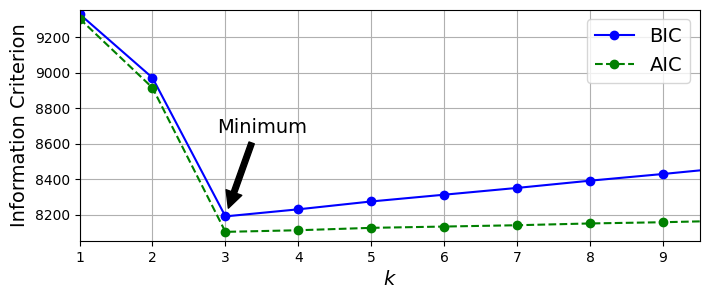

In [74]:
gms_per_k = [
    GaussianMixture(n_components=k, n_init=10, random_state=42).fit(X)
    for k in range(1, 11)
]
bics = [model.bic(X) for model in gms_per_k]
aics = [model.aic(X) for model in gms_per_k]

plt.figure(figsize=(8, 3))
plt.plot(range(1, 11), bics, "bo-", label="BIC")
plt.plot(range(1, 11), aics, "go--", label="AIC")
plt.xlabel("$k$")
plt.ylabel("Information Criterion")
plt.axis([1, 9.5, min(aics) - 50, max(aics) + 50])
plt.annotate(
    "",
    xy=(3, bics[2]),
    xytext=(3.4, 8650),
    arrowprops=dict(facecolor="black", shrink=0.1),
)
plt.text(3.5, 8660, "Minimum", horizontalalignment="center")
plt.legend()
plt.grid()
plt.show()

### Bayesian Gaussian Mixture Models

They are capable of giving weights equal (or close) to zero to unnecessary clusters. Set the `n_components` to a value that we have good reason to believe is greater than the optimal number of clusters.

In [75]:
from sklearn.mixture import BayesianGaussianMixture

bgm = BayesianGaussianMixture(
    n_components=10, n_init=10, max_iter=500, random_state=42
)
bgm.fit(X)
bgm.weights_.round(2)

array([0.4 , 0.21, 0.39, 0.  , 0.  , 0.  , 0.  , 0.  , 0.  , 0.  ])

About GMMs:
- Work great on clusters with ellipsoidal shapes.
- Don’t do so well with clusters of very different shapes.

### Other Algorithms for Anomaly and Novelty Detection
<style>*:not(li) > ul {list-style-type: none;}</style>

*Fast-MCD (minimum covariance determinant)*
- Implemented by the `EllipticEnvelope` class, this algorithm is useful for outlier detection, in particular to clean up a dataset. It assumes that the normal instances (inliers) are generated from a single Gaussian distribution (not a mixture). It also assumes that the dataset is contaminated with outliers that were not generated from this Gaussian distribution. When the algorithm estimates the parameters of the Gaussian distribution (i.e., the shape of the elliptic envelope around the inliers), it is careful to ignore the instances that are most likely outliers. This technique gives a better estimation of the elliptic envelope and thus makes the algorithm better at identifying the outliers.

*Isolation forest*
- This is an efficient algorithm for outlier detection, especially in high-dimensional datasets. The algorithm builds a random forest in which each decision tree is grown randomly: at each node, it picks a feature randomly, then it picks a random threshold value (between the min and max values) to split the dataset in two. The dataset gradually gets chopped into pieces this way, until all instances end up isolated from the other instances. Anomalies are usually far from other instances, so on average (across all the decision trees) they tend to get isolated in fewer steps than normal instances.

*Local outlier factor (LOF)*
- This algorithm is also good for outlier detection. It compares the density of instances around a given instance to the density around its neighbors. An anomaly is often more isolated than its *k*-nearest neighbors.

*One-class SVM*
- This algorithm is better suited for novelty detection. Recall that a kernelized SVM classifier separates two classes by first (implicitly) mapping all the instances to a high-dimensional space, then separating the two classes using a linear SVM classifier within this high-dimensional space. Since we just have one class of instances, the one-class SVM algorithm instead tries to separate the instances in high-dimensional space from the origin. In the original space, this will correspond to finding a small region that encompasses all the instances. If a new instance does not fall within this region, it is an anomaly. There are a few hyperparameters to tweak:
  - The usual ones for a kernelized SVM
  - A margin hyperparameter that corresponds to the probability of a new
    instance being mistakenly considered as novel when it is in fact normal.

  This approach:
  - Works great with high-dimensional datasets.
  - Scales poorly with $m$.

*PCA and other dimensionality reduction techniques with an* `inverse_transform()` *method*
- If we compare the reconstruction error of a normal instance with the reconstruction error of an anomaly, the latter will usually be much larger. This is a simple and often quite efficient anomaly detection approach.

## Exercises

### 1. to 10.
1. How would we define clustering? Can we name a few clustering algorithms?
> In machine learning, clustering is the unsupervised task of grouping similar instances together. The notion of similarity depends on the task at hand: e.g. in some cases two nearby instances will be considered similar, while in others similar instances may be far apart as long as they belong to the same densely packed group. Popular clustering algorithms include *k*-means, DBSCAN, agglomerative clustering, BIRCH, mean-shift, affinity propagation, and spectral clustering.
2. What are some of the main applications of clustering algorithms?
> The main applications of clustering algorithms include data analysis, customer segmentation, recommender systems, search engines, image segmentation, semi-supervised learning, dimensionality reduction, anomaly detection, and novelty detection.
3. Describe two techniques to select the right number of clusters when using *k*-means.
> The elbow rule is a simple technique to select the number of clusters when using *k*-means: just plot the inertia (the mean squared distance from each instance to its nearest centroid) as a function of the number of clusters, and find the point in the curve where the inertia stops dropping fast (the elbow). This is generally close to the optimal number of clusters. Another approach is to plot the silhouette score as a function of the number of clusters. There will often be a peak, and the optimal number of clusters is generally nearby. The silhouette score is the mean silhouette coefficient over all instances. This coefficient varies from +1 for instances that are well inside their cluster and far from other clusters, to –1 for instances that are very close to another cluster. we may also plot the silhouette diagrams and perform a more thorough analysis.
4. What is label propagation? Why would we implement it, and how?
> Labeling a dataset is costly and time-consuming. Therefore, it is common to have plenty of unlabeled instances, but few labeled instances. Label propagation is a technique that consists in copying some (or all) of the labels from the labeled instances to similar unlabeled instances. This can greatly extend the number of labeled instances, and thereby allow a supervised algorithm to reach better performance (this is a form of semi-supervised learning). One approach is to use a clustering algorithm such as *k*-means on all the instances, then for each cluster find the most common label or the label of the most representative instance (i.e., the one closest to the centroid) and propagate it to the unlabeled instances in the same cluster.
5. Can we name two clustering algorithms that can scale to large datasets? And two that look for regions of high density?
> *k*-Means and BIRCH scale well to large datasets. DBSCAN and mean-shift look for regions of high density.
6. Can we think of a use case where active learning would be useful? How would we implement it?
> Active learning is useful whenever we have plenty of unlabeled instances but labeling is costly. In this case (which is very common), rather than randomly selecting instances to label, it is often preferable to perform active learning, where human experts interact with the learning algorithm, providing labels for specific instances when the algorithm requests them. A common approach is uncertainty sampling.
7. What is the difference between anomaly detection and novelty detection?
> Many people use the terms *anomaly detection* and *novelty detection* interchangeably, but they are not exactly the same. In anomaly detection, the algorithm is trained on a dataset that may contain outliers, and the goal is typically to identify these outliers (within the training set), as well as outliers among new instances. In novelty detection, the algorithm is trained on a dataset that is presumed to be "clean," and the objective is to detect novelties strictly among new instances. Some algorithms work best for anomaly detection (e.g. isolation forest), while others are better suited for novelty detection (e.g. one-class SVM).
8. What is a Gaussian mixture? What tasks can we use it for?
> A Gaussian mixture model (GMM) is a probabilistic model that assumes that the instances were generated from a mixture of several Gaussian distributions whose parameters are unknown. In other words, the assumption is that the data is grouped into a finite number of clusters, each with an ellipsoidal shape (but the clusters may have different ellipsoidal shapes, sizes, orientations, and densities), and we don’t know which cluster each instance belongs to. This model is useful for density estimation, clustering, and anomaly detection.
9. Can we name two techniques to find the right number of clusters when using a Gaussian mixture model?
> One way to find the right number of clusters when using a Gaussian mixture model is to plot the Bayesian information criterion (BIC) or the Akaike information criterion (AIC) as a function of the number of clusters, then choose the number of clusters that minimizes the BIC or AIC. Another technique is to use a Bayesian Gaussian mixture model, which automatically selects the number of clusters.
10. The classic Olivetti faces dataset contains 400 grayscale 64 $\times$ 64–pixel images of faces. Each image is flattened to a 1D vector of size 4,096. 40 different people were photographed (10 times each), and the usual task is to train a model that can predict which person is represented in each picture. Load the dataset using the `sklearn.datasets.fetch_olivetti_faces()` function.

**Warning**: The `fetch_olivetti_faces()` function can fail with an HTTP 403 error in Google Colab because the platform that hosts the data ([figshare.com](https://figshare.com)) blocks Google Cloud IP addresses. To bypass this, the code below downloads a cached mirror of the dataset from the [ageron/data](https://github.com/ageron/data) repository directly into Scikit-Learn’s expected directory.

In [76]:
import urllib.request
from pathlib import Path

from sklearn.datasets import get_data_home

data_home = Path(get_data_home())
data_home.mkdir(parents=True, exist_ok=True)
local_file_path = data_home / "olivetti_py3.pkz"
if not local_file_path.exists():
    url = "https://github.com/ageron/data/raw/refs/heads/main/olivetti_py3.pkz"
    print(f"Downloading Olivetti faces from {url} to {local_file_path}\n")
    urllib.request.urlretrieve(url, local_file_path)

In [77]:
from sklearn.datasets import fetch_olivetti_faces

olivetti = fetch_olivetti_faces()

In [78]:
print(olivetti.DESCR)

.. _olivetti_faces_dataset:

The Olivetti faces dataset
--------------------------

`This dataset contains a set of face images`_ taken between April 1992 and
April 1994 at AT&T Laboratories Cambridge. The
:func:`sklearn.datasets.fetch_olivetti_faces` function is the data
fetching / caching function that downloads the data
archive from AT&T.

.. _This dataset contains a set of face images: https://cam-orl.co.uk/facedatabase.html

As described on the original website:

    There are ten different images of each of 40 distinct subjects. For some
    subjects, the images were taken at different times, varying the lighting,
    facial expressions (open / closed eyes, smiling / not smiling) and facial
    details (glasses / no glasses). All the images were taken against a dark
    homogeneous background with the subjects in an upright, frontal position
    (with tolerance for some side movement).

**Data Set Characteristics:**

=================   =====================
Classes              

In [79]:
olivetti.target

array([ 0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  1,  1,  1,  1,  1,  1,  1,
        1,  1,  1,  2,  2,  2,  2,  2,  2,  2,  2,  2,  2,  3,  3,  3,  3,
        3,  3,  3,  3,  3,  3,  4,  4,  4,  4,  4,  4,  4,  4,  4,  4,  5,
        5,  5,  5,  5,  5,  5,  5,  5,  5,  6,  6,  6,  6,  6,  6,  6,  6,
        6,  6,  7,  7,  7,  7,  7,  7,  7,  7,  7,  7,  8,  8,  8,  8,  8,
        8,  8,  8,  8,  8,  9,  9,  9,  9,  9,  9,  9,  9,  9,  9, 10, 10,
       10, 10, 10, 10, 10, 10, 10, 10, 11, 11, 11, 11, 11, 11, 11, 11, 11,
       11, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 13, 13, 13, 13, 13, 13,
       13, 13, 13, 13, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 15, 15, 15,
       15, 15, 15, 15, 15, 15, 15, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16,
       17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 18, 18, 18, 18, 18, 18, 18,
       18, 18, 18, 19, 19, 19, 19, 19, 19, 19, 19, 19, 19, 20, 20, 20, 20,
       20, 20, 20, 20, 20, 20, 21, 21, 21, 21, 21, 21, 21, 21, 21, 21, 22,
       22, 22, 22, 22, 22

Then split it into a training set, a validation set, and a test set (note that the dataset is already scaled between 0 and 1). Since the dataset is quite small, we probably want to use stratified sampling to ensure that there are the same number of images per person in each set.

In [80]:
from sklearn.model_selection import StratifiedShuffleSplit

strat_split = StratifiedShuffleSplit(n_splits=1, test_size=40, random_state=42)
train_valid_idx, test_idx = next(
    strat_split.split(olivetti.data, olivetti.target)
)
X_train_valid = olivetti.data[train_valid_idx]
y_train_valid = olivetti.target[train_valid_idx]
X_test = olivetti.data[test_idx]
y_test = olivetti.target[test_idx]

strat_split = StratifiedShuffleSplit(n_splits=1, test_size=80, random_state=43)
train_idx, valid_idx = next(strat_split.split(X_train_valid, y_train_valid))
X_train = X_train_valid[train_idx]
y_train = y_train_valid[train_idx]
X_valid = X_train_valid[valid_idx]
y_valid = y_train_valid[valid_idx]

In [81]:
print(X_train.shape, y_train.shape)
print(X_valid.shape, y_valid.shape)
print(X_test.shape, y_test.shape)

(280, 4096) (280,)
(80, 4096) (80,)
(40, 4096) (40,)


> To speed things up, we’ll reduce the data’s dimensionality using PCA:

In [82]:
from sklearn.decomposition import PCA

pca = PCA(0.99)
X_train_pca = pca.fit_transform(X_train)
X_valid_pca = pca.transform(X_valid)
X_test_pca = pca.transform(X_test)

pca.n_components_

np.int64(199)

Next, cluster the images using *k*-means, and ensure that we have a good number of clusters (using one of the techniques discussed in this chapter).

In [83]:
from sklearn.cluster import KMeans

k_range = range(5, 150, 5)
kmeans_per_k = []
for k in k_range:
    print(f"k={k}")
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_train_pca)
    kmeans_per_k.append(kmeans)

k=5
k=10
k=15
k=20
k=25
k=30
k=35
k=40
k=45
k=50
k=55
k=60
k=65
k=70
k=75
k=80
k=85
k=90
k=95
k=100
k=105
k=110
k=115
k=120
k=125
k=130
k=135
k=140
k=145


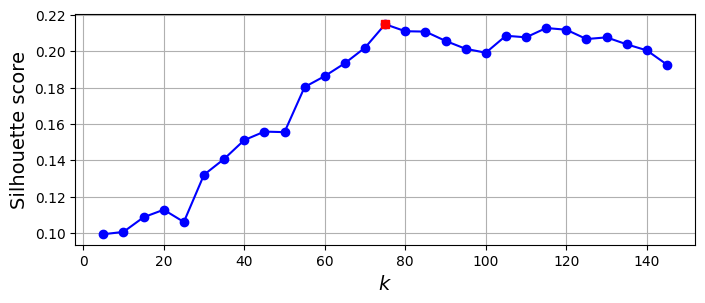

In [84]:
from sklearn.metrics import silhouette_score

silhouette_scores = [
    silhouette_score(X_train_pca, model.labels_) for model in kmeans_per_k
]
best_index = np.argmax(silhouette_scores)
best_k = k_range[best_index]
best_score = silhouette_scores[best_index]

plt.figure(figsize=(8, 3))
plt.plot(k_range, silhouette_scores, "bo-")
plt.xlabel("$k$")
plt.ylabel("Silhouette score")
plt.plot(best_k, best_score, "rs")
plt.grid()
plt.show()

In [85]:
best_k

75

> It looks like the best number of clusters is quite high, at 75. We might have expected it to be 40, since there are 40 different people on the pictures. However, the same person may look quite different on different pictures (e.g., with or without glasses, or simply shifted left or right).

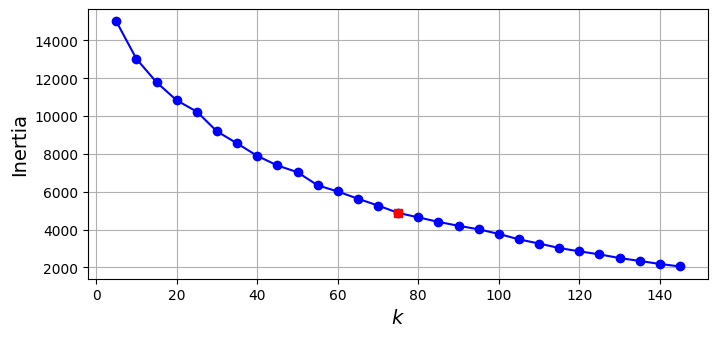

In [86]:
inertias = [model.inertia_ for model in kmeans_per_k]
best_inertia = inertias[best_index]

plt.figure(figsize=(8, 3.5))
plt.plot(k_range, inertias, "bo-")
plt.xlabel("$k$")
plt.ylabel("Inertia")
plt.plot(best_k, best_inertia, "rs")
plt.grid()
plt.show()

> The optimal number of clusters is not clear on this inertia diagram, as there is no obvious elbow, so let’s stick with k=75.

In [87]:
best_model = kmeans_per_k[best_index]

Visualize the clusters: do we see similar faces in each cluster?

Cluster 0


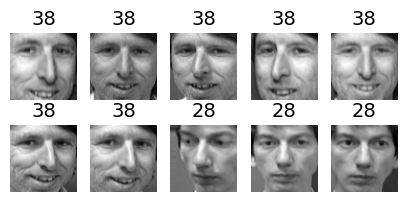

Cluster 1


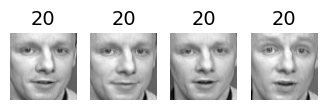

Cluster 2


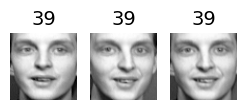

Cluster 3


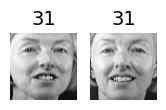

Cluster 4


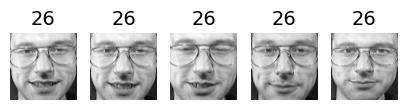

Cluster 5


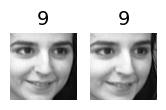

Cluster 6


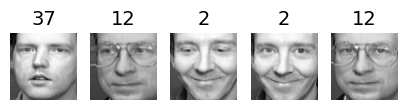

Cluster 7


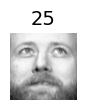

Cluster 8


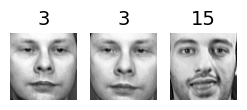

Cluster 9


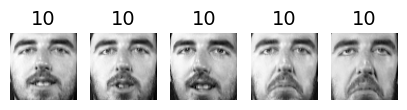

Cluster 10


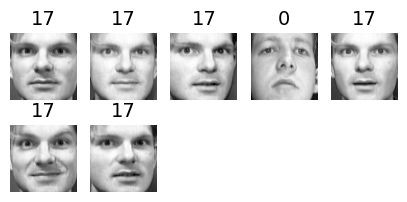

Cluster 11


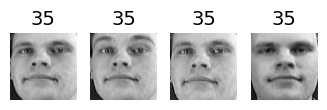

Cluster 12


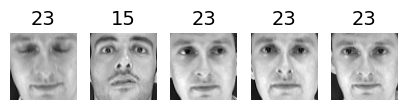

Cluster 13


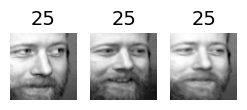

Cluster 14


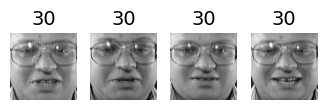

Cluster 15


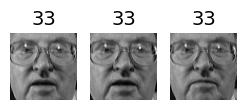

Cluster 16


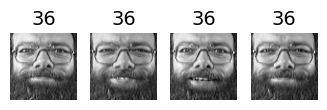

Cluster 17


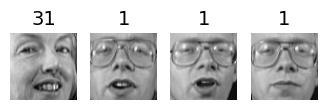

Cluster 18


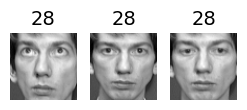

Cluster 19


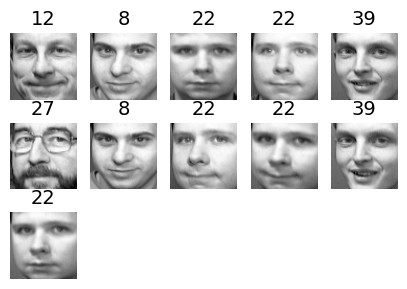

Cluster 20


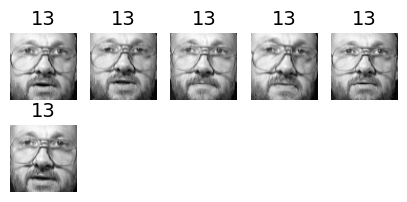

Cluster 21


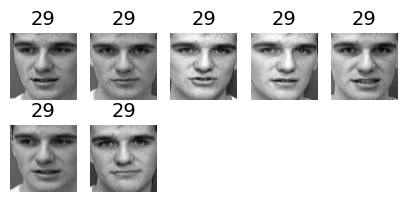

Cluster 22


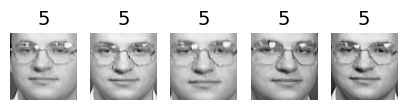

Cluster 23


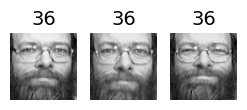

Cluster 24


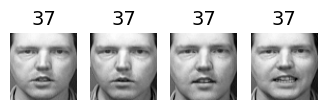

Cluster 25


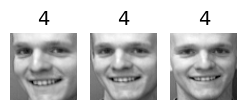

Cluster 26


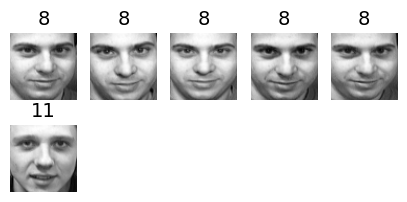

Cluster 27


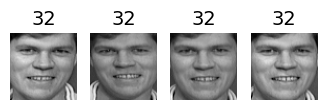

Cluster 28


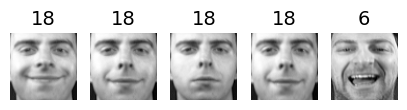

Cluster 29


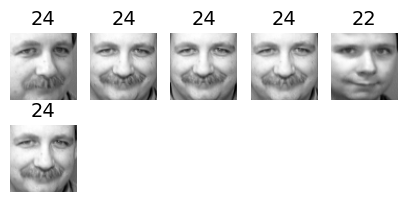

Cluster 30


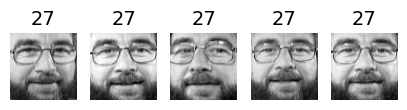

Cluster 31


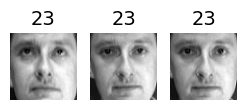

Cluster 32


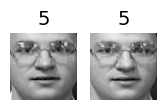

Cluster 33


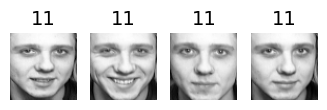

Cluster 34


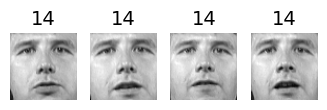

Cluster 35


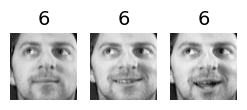

Cluster 36


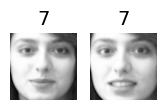

Cluster 37


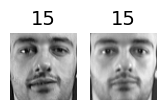

Cluster 38


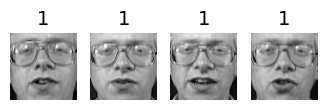

Cluster 39


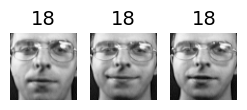

Cluster 40


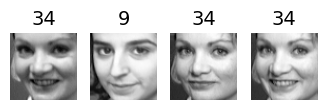

Cluster 41


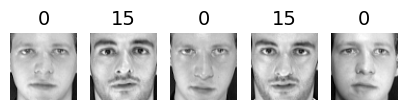

Cluster 42


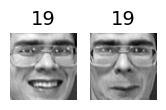

Cluster 43


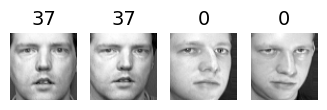

Cluster 44


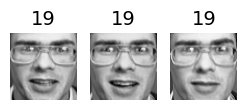

Cluster 45


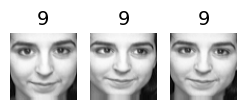

Cluster 46


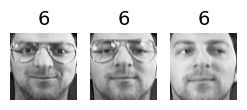

Cluster 47


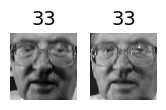

Cluster 48


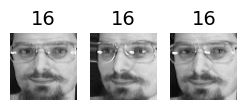

Cluster 49


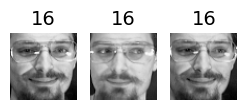

Cluster 50


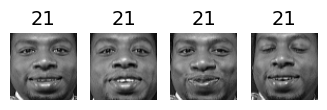

Cluster 51


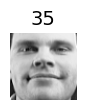

Cluster 52


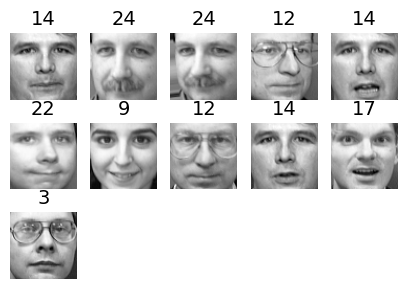

Cluster 53


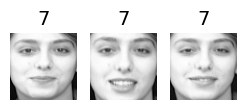

Cluster 54


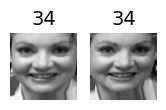

Cluster 55


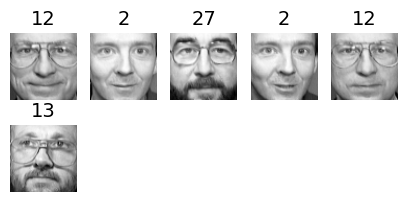

Cluster 56


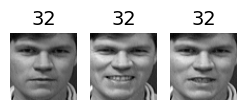

Cluster 57


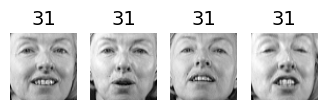

Cluster 58


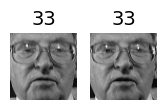

Cluster 59


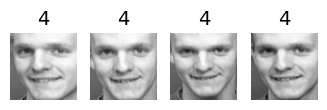

Cluster 60


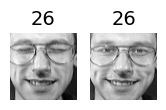

Cluster 61


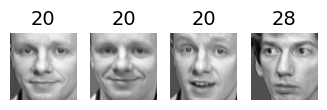

Cluster 62


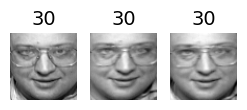

Cluster 63


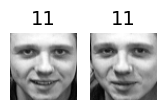

Cluster 64


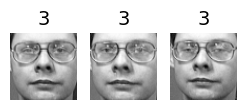

Cluster 65


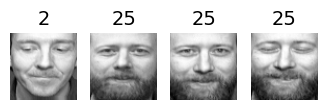

Cluster 66


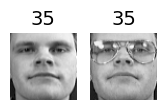

Cluster 67


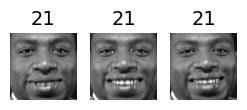

Cluster 68


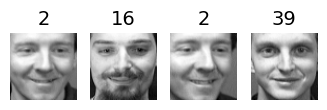

Cluster 69


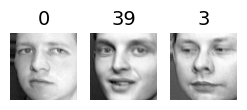

Cluster 70


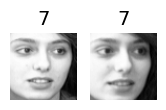

Cluster 71


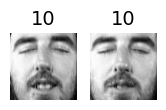

Cluster 72


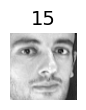

Cluster 73


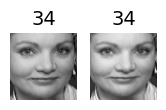

Cluster 74


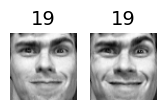

In [88]:
def plot_faces(faces: np.ndarray, labels: np.ndarray, n_cols: int = 5) -> None:
    faces = faces.reshape(-1, 64, 64)
    n_rows = (len(faces) - 1) // n_cols + 1
    plt.figure(figsize=(n_cols, n_rows * 1.1))
    for index, (face, label) in enumerate(zip(faces, labels)):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(face, cmap="gray")
        plt.axis("off")
        plt.title(label)
    plt.show()


for cluster_id in np.unique(best_model.labels_):
    print("Cluster", cluster_id)
    in_cluster = best_model.labels_ == cluster_id
    faces = X_train[in_cluster]
    labels = y_train[in_cluster]
    plot_faces(faces, labels)

> About 2 out of 3 clusters are useful: that is, they contain at least 2 pictures, all of the same person. However, the rest of the clusters have either one or more intruders, or they have just a single picture.
>
> Clustering images this way may be too imprecise to be directly useful when training a model (as we will see below), but it can be tremendously useful when labeling images in a new dataset: it will usually make labeling much faster.

### 11.
Continuing with the Olivetti faces dataset, train a classifier to predict which person is represented in each picture, and evaluate it on the validation set.

In [89]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(n_estimators=150, random_state=42)
clf.fit(X_train_pca, y_train)
clf.score(X_valid_pca, y_valid)

0.925

Next, use *k*-means as a dimensionality reduction tool, and train a classifier on the reduced set.

In [90]:
X_train_reduced = best_model.transform(X_train_pca)
X_valid_reduced = best_model.transform(X_valid_pca)
X_test_reduced = best_model.transform(X_test_pca)

clf = RandomForestClassifier(n_estimators=150, random_state=42)
clf.fit(X_train_reduced, y_train)

clf.score(X_valid_reduced, y_valid)

0.7375

> Yikes! That’s not better at all! Let’s see if tuning the number of clusters helps.

Search for the number of clusters that allows the classifier to get the best performance: what performance can we reach?
> We could use a `GridSearchCV` like we did earlier in this notebook, but since we already have a validation set, we don’t need *k*-fold cross-validation, and we’re only exploring a single hyperparameter, so it’s simpler to just run a loop manually:

In [91]:
from sklearn.pipeline import make_pipeline

for n_clusters in k_range:
    pipeline = make_pipeline(
        KMeans(n_clusters=n_clusters, random_state=42),
        RandomForestClassifier(n_estimators=150, random_state=42),
    )
    pipeline.fit(X_train_pca, y_train)
    print(n_clusters, pipeline.score(X_valid_pca, y_valid))

5 0.4125
10 0.4375
15 0.5875
20 0.6125
25 0.6625
30 0.6625
35 0.6625
40 0.675
45 0.6875
50 0.6875
55 0.75
60 0.7
65 0.725
70 0.7
75 0.7375
80 0.725
85 0.75
90 0.775
95 0.775
100 0.7625
105 0.7375
110 0.725
115 0.7625
120 0.7625
125 0.7625
130 0.725
135 0.7125
140 0.8
145 0.725


> Oh well, even by tuning the number of clusters, we never get beyond 80% accuracy. Looks like the distances to the cluster centroids are not as informative as the original images.

What if we append the features from the reduced set to the original features (again, searching for the best number of clusters)?

In [92]:
X_train_extended = np.c_[X_train_pca, X_train_reduced]
X_valid_extended = np.c_[X_valid_pca, X_valid_reduced]
X_test_extended = np.c_[X_test_pca, X_test_reduced]

In [93]:
clf = RandomForestClassifier(n_estimators=150, random_state=42)
clf.fit(X_train_extended, y_train)
clf.score(X_valid_extended, y_valid)

0.85

> That’s a bit better, but still worse than without the cluster features. The clusters are not useful to directly train a classifier in this case (but they can still help when labeling new training instances).

### 12.
Train a Gaussian mixture model on the Olivetti faces dataset. To speed up the algorithm, we should probably reduce the dataset’s dimensionality (e.g., use PCA, preserving 99% of the variance).

In [94]:
from sklearn.mixture import GaussianMixture

gm = GaussianMixture(n_components=40, random_state=42)
y_pred = gm.fit_predict(X_train_pca)

Use the model to generate some new faces (using the `sample()` method), and visualize them (if we used PCA, we will need to use its `inverse_transform()` method).

In [95]:
n_gen_faces = 20
gen_faces_reduced, y_gen_faces = gm.sample(n_samples=n_gen_faces)
gen_faces = pca.inverse_transform(gen_faces_reduced)

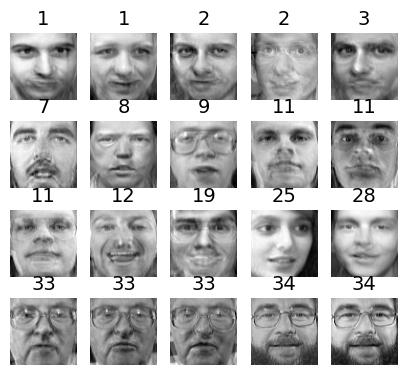

In [96]:
plot_faces(gen_faces, y_gen_faces)

Try to modify some images (e.g., rotate, flip, darken) and see if the model can detect the anomalies (i.e., compare the output of the `score_samples()` method for normal images and for anomalies).

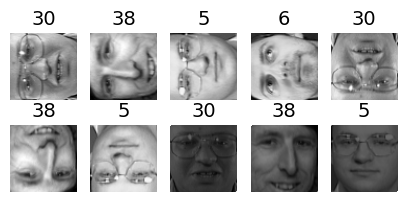

In [97]:
n_rotated = 4
rotated = np.transpose(X_train[:n_rotated].reshape(-1, 64, 64), axes=[0, 2, 1])
rotated = rotated.reshape(-1, 64 * 64)
y_rotated = y_train[:n_rotated]

n_flipped = 3
flipped = X_train[:n_flipped].reshape(-1, 64, 64)[:, ::-1]
flipped = flipped.reshape(-1, 64 * 64)
y_flipped = y_train[:n_flipped]

n_darkened = 3
darkened = X_train[:n_darkened].copy()
darkened[:, 1:-1] *= 0.3
y_darkened = y_train[:n_darkened]

X_bad_faces = np.r_[rotated, flipped, darkened]
y_bad = np.concatenate([y_rotated, y_flipped, y_darkened])

plot_faces(X_bad_faces, y_bad)

In [98]:
X_bad_faces_pca = pca.transform(X_bad_faces)

In [99]:
gm.score_samples(X_bad_faces_pca)

array([-1.8862228e+07, -1.7601792e+07, -4.1554208e+07, -4.9378872e+07,
       -3.2427920e+07, -1.3422791e+07, -2.9008060e+07, -9.4334328e+07,
       -1.0486777e+08, -5.4890616e+07], dtype=float32)

> The bad faces are all considered highly unlikely by the Gaussian mixture model. Compare this to the scores of some training instances:

In [100]:
gm.score_samples(X_train_pca[:10])

array([1163.1475, 1112.3865, 1156.327 , 1170.703 , 1074.0399, 1139.968 ,
       1113.8505, 1074.0399, 1048.2206, 1048.2206], dtype=float32)

### 13.
Some dimensionality reduction techniques can also be used for anomaly detection. e.g., take the Olivetti faces dataset and reduce it with PCA, preserving 99% of the variance. Then compute the reconstruction error for each image. Next, take some of the modified images we built in the previous exercise, and look at their reconstruction error: notice how much larger the reconstruction error is. If we plot a reconstructed image, we will see why: it tries to reconstruct a normal face.
> We already reduced the dataset using PCA earlier:

In [101]:
X_train_pca.round(2)

array([[ -3.78,   1.85,  -5.14, ...,   0.14,  -0.21,   0.06],
       [-10.15,   1.53,  -0.77, ...,  -0.12,  -0.14,  -0.02],
       [ 10.02,  -2.88,  -0.92, ...,  -0.07,  -0.  ,   0.12],
       ...,
       [ -2.48,  -2.96,   1.3 , ...,   0.02,   0.03,  -0.15],
       [  3.22,  -5.35,   1.39, ...,  -0.06,  -0.23,   0.16],
       [  0.92,   3.65,   2.26, ...,  -0.14,  -0.07,   0.06]],
      shape=(280, 199), dtype=float32)

In [102]:
def reconstruction_errors(pca: Pipeline, X: np.ndarray) -> float:
    X_pca = pca.transform(X)
    X_reconstructed = pca.inverse_transform(X_pca)
    mse = np.square(X_reconstructed - X).mean(axis=-1)
    return mse

In [103]:
reconstruction_errors(pca, X_train).mean()

np.float32(0.00019205351)

In [104]:
reconstruction_errors(pca, X_bad_faces).mean()

np.float32(0.004707354)

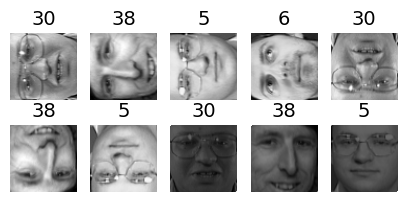

In [105]:
plot_faces(X_bad_faces, y_bad)

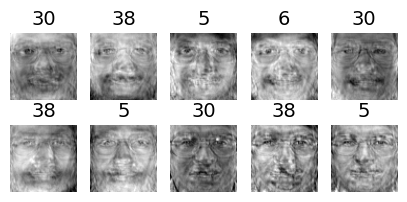

In [106]:
X_bad_faces_reconstructed = pca.inverse_transform(X_bad_faces_pca)
plot_faces(X_bad_faces_reconstructed, y_bad)